In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stat


In [ ]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

In [5]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [7]:
df.shape

(5110, 12)

In [8]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [9]:
df['bmi'].info()

<class 'pandas.Series'>
RangeIndex: 5110 entries, 0 to 5109
Series name: bmi
Non-Null Count  Dtype  
--------------  -----  
4909 non-null   float64
dtypes: float64(1)
memory usage: 40.1 KB


In [10]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [15]:
y = df['stroke']

y

0       1
1       1
2       1
3       1
4       1
       ..
5105    0
5106    0
5107    0
5108    0
5109    0
Name: stroke, Length: 5110, dtype: int64

In [21]:
X = df.drop(columns='stroke')

In [22]:
X.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked


In [23]:
X.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000


In [24]:
numeric_col = X.select_dtypes(include=np.number).columns.tolist()

In [25]:
numeric_col

['id', 'age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']

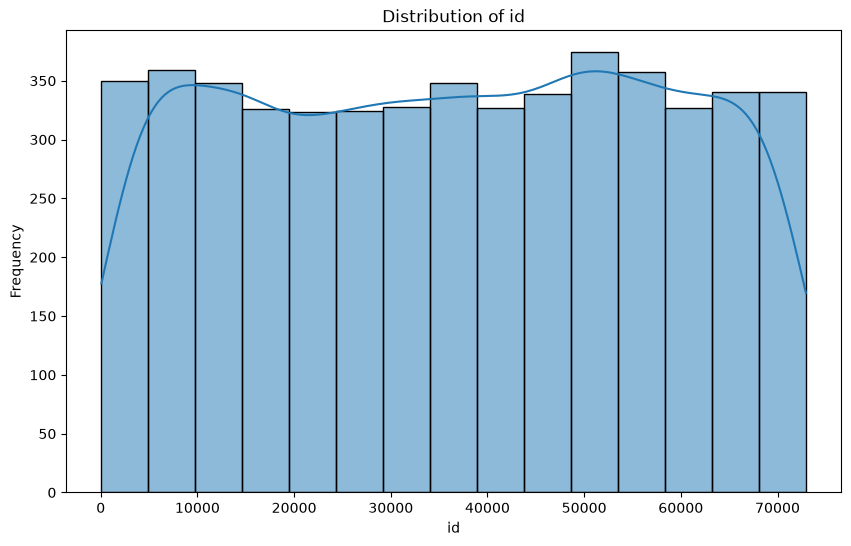

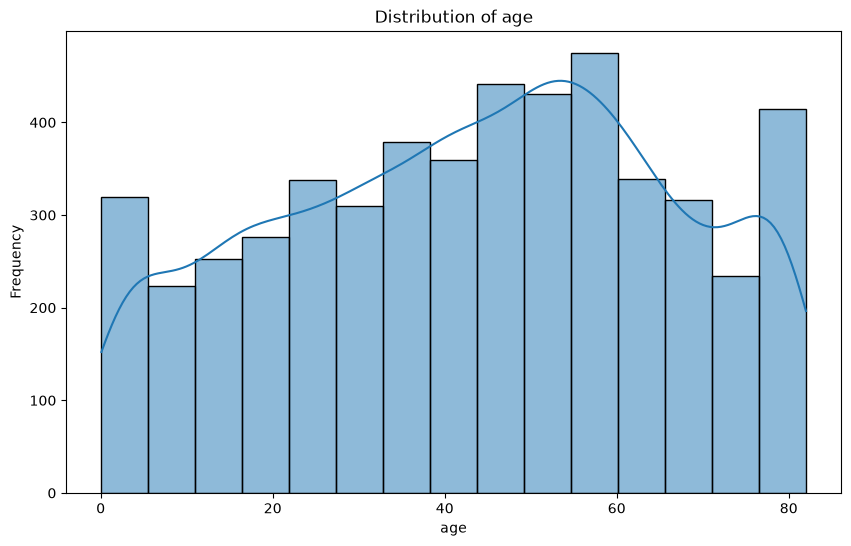

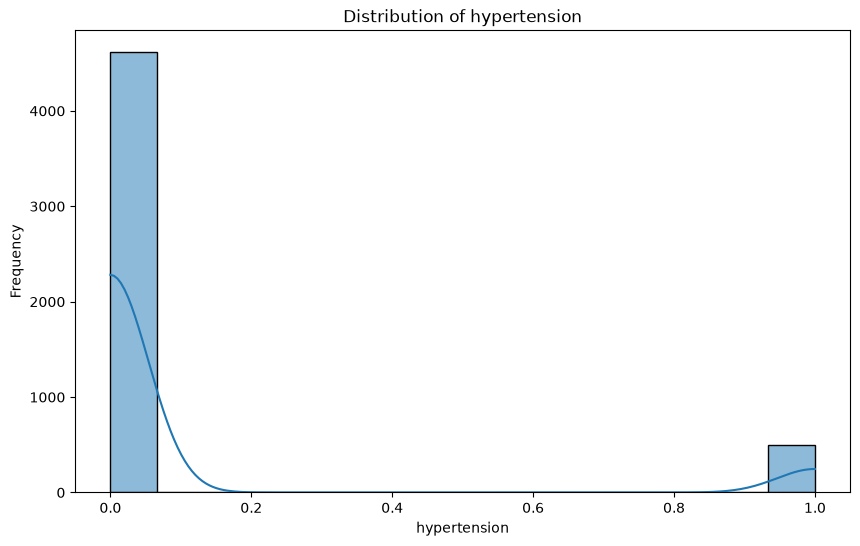

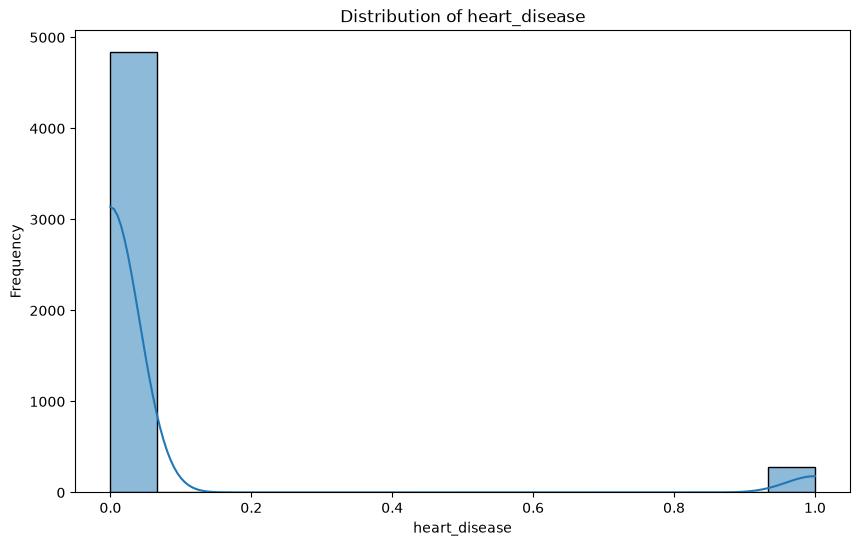

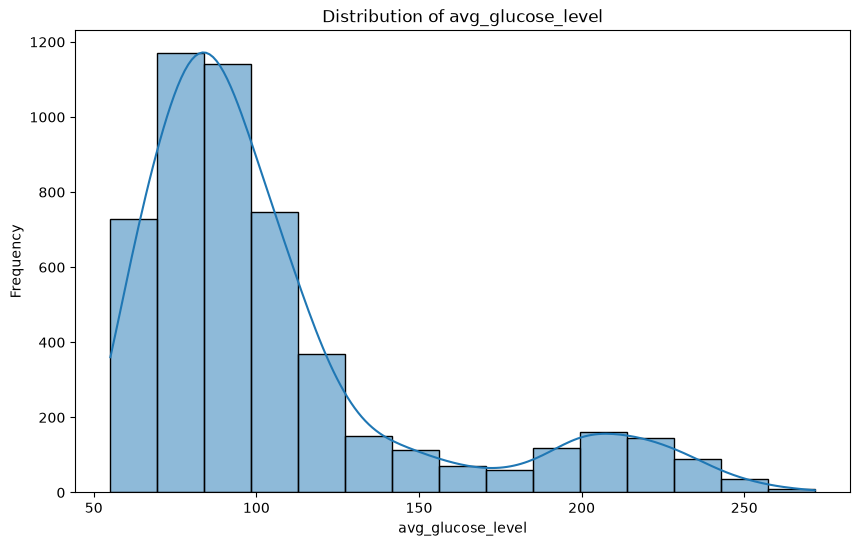

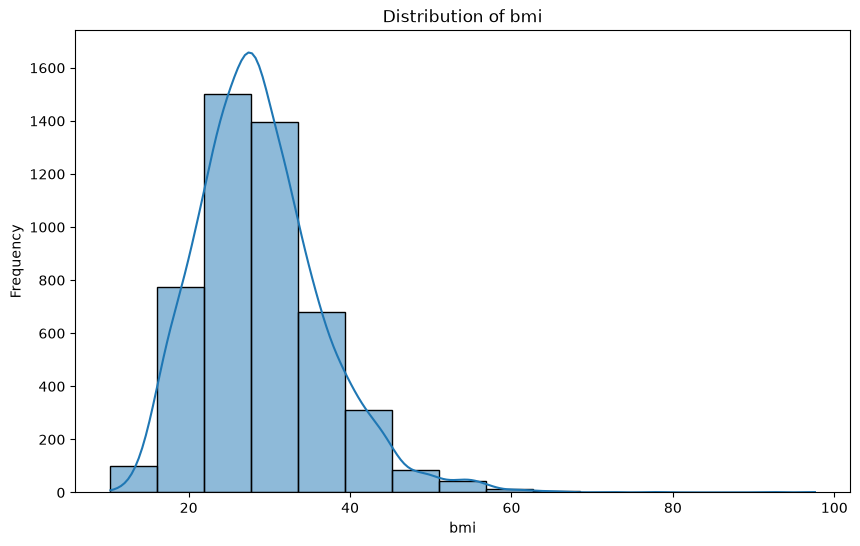

In [31]:
for col in numeric_col:
    plt.figure(figsize=(10,6))

    sns.histplot(data=df, x=col, kde=True,bins=15)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

In [ ]:
X['hypertension'].unique()


array([0, 1])

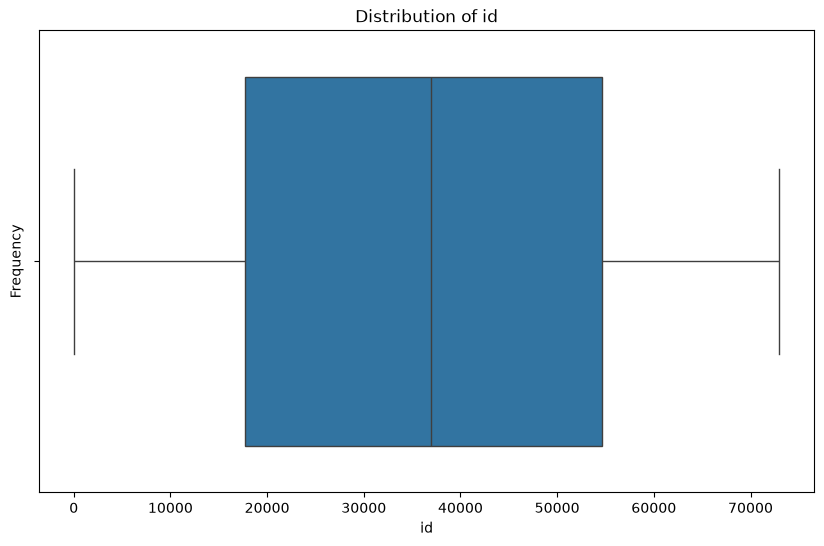

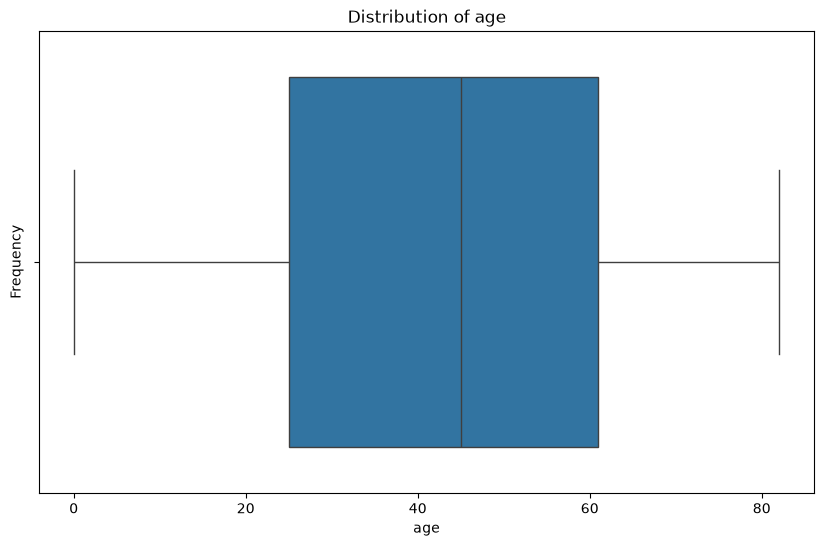

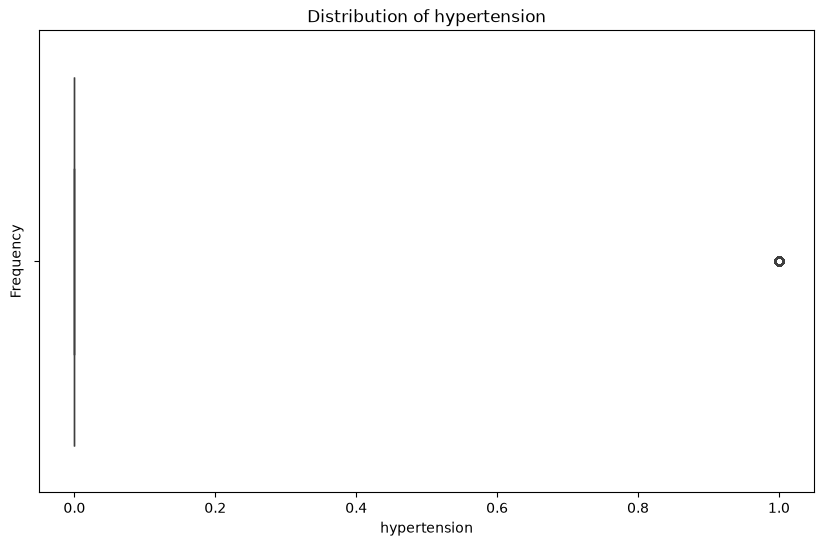

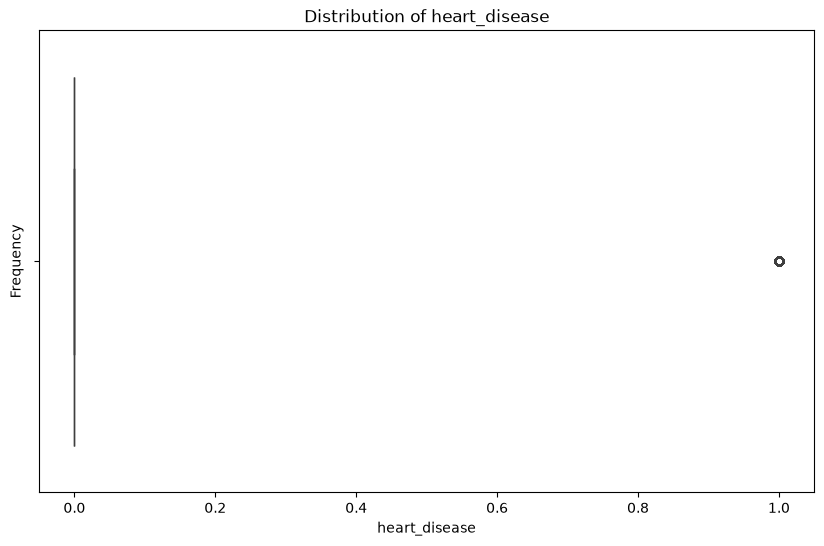

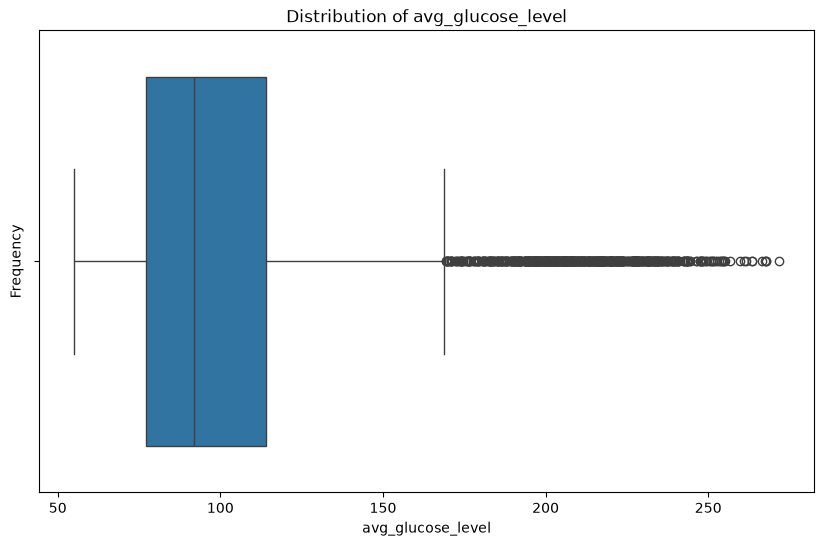

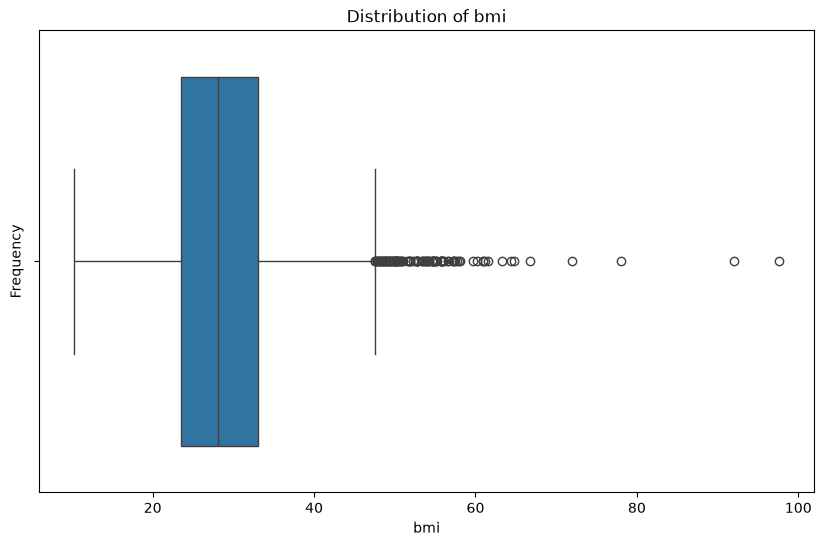

In [35]:
for col in numeric_col:
    plt.figure(figsize=(10,6))

    sns.boxplot(data=df,x=col)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

In [38]:
categoric_col = X.select_dtypes(include='str').columns.tolist()

categoric_col

['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

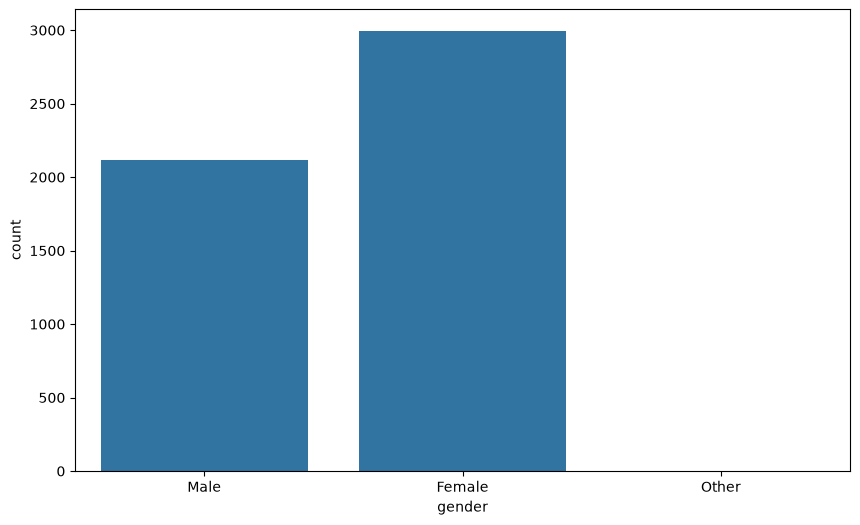

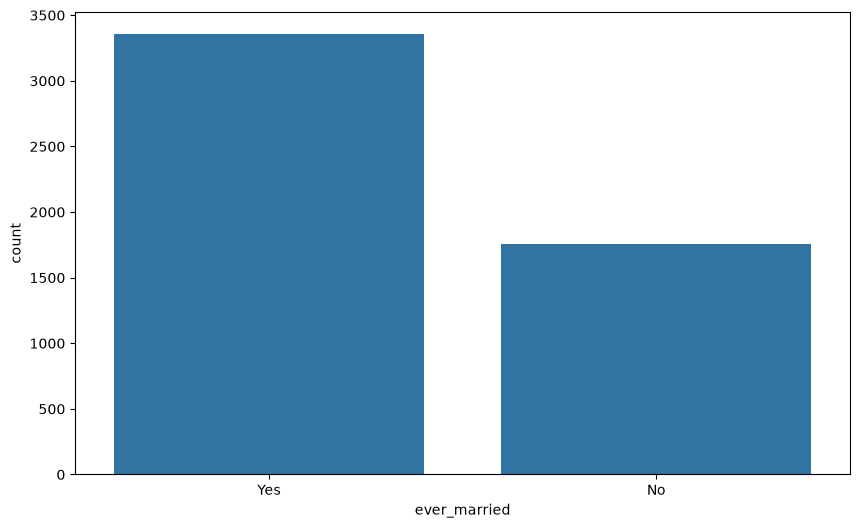

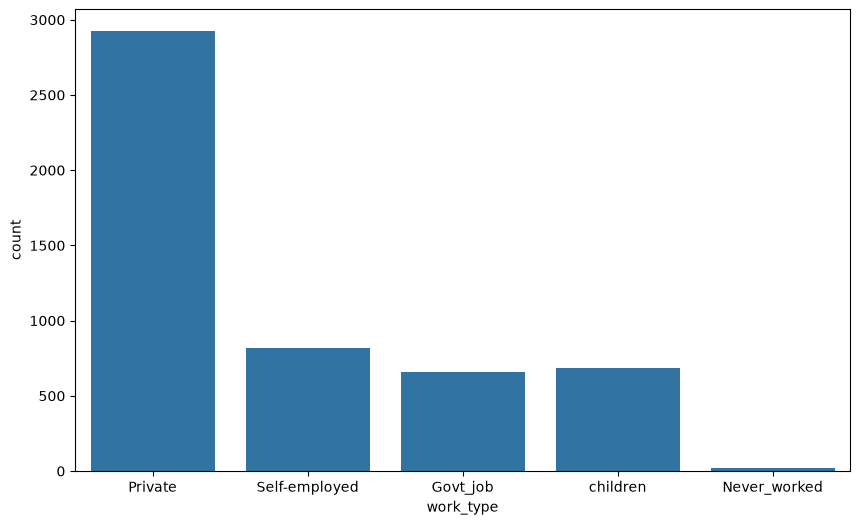

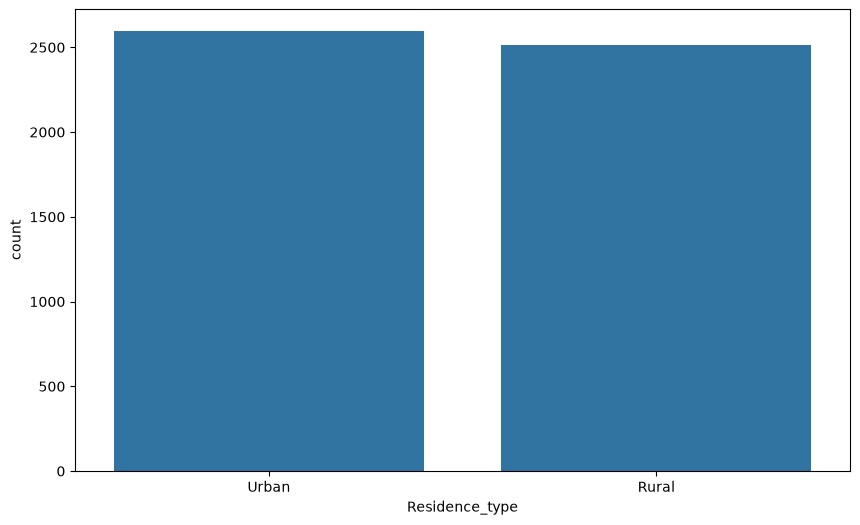

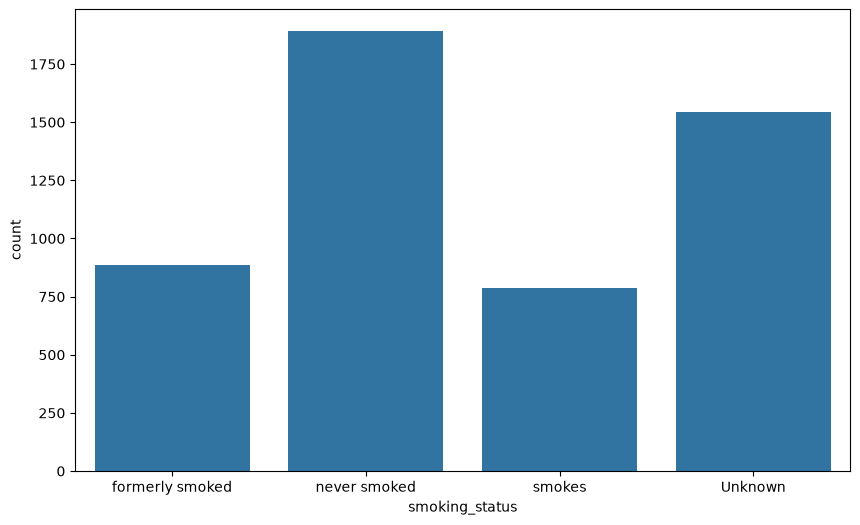

In [41]:
for col in categoric_col:
    plt.figure(figsize=(10,6))

    sns.countplot(data=df,x=col)

    plt.show()

In [42]:
X['gender'].unique()

<StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str

In [43]:
X['gender'].value_counts()

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

In [45]:
X['avg_glucose_level'].describe()

count    5110.000000
mean      106.147677
std        45.283560
min        55.120000
25%        77.245000
50%        91.885000
75%       114.090000
max       271.740000
Name: avg_glucose_level, dtype: float64

In [46]:
X['bmi'].describe()

count    4909.000000
mean       28.893237
std         7.854067
min        10.300000
25%        23.500000
50%        28.100000
75%        33.100000
max        97.600000
Name: bmi, dtype: float64

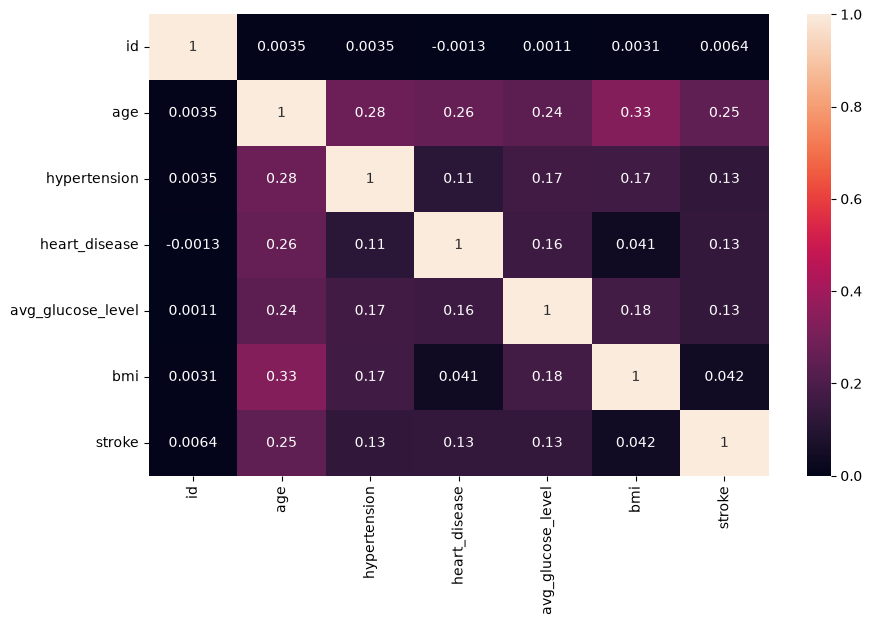

In [47]:
plt.figure(figsize=(10,6))

sns.heatmap(df.corr(numeric_only=True),annot=True)

plt.show()

In [80]:
X_cleaned = df.copy()

X_cleaned.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [63]:
X_cleaned.shape

(5110, 12)

In [62]:
X_cleaned.drop_duplicates(inplace=True)

/var/folders/cw/2t1py2jn5jx2mszgmmhcm0f00000gn/T/ipykernel_38062/4077997809.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_cleaned.drop_duplicates(inplace=True)


In [64]:
X_cleaned.shape

(5110, 12)

In [65]:
X_cleaned.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')

In [66]:
X_cleaned.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [81]:
X_cleaned['bmi'].head()

0    36.6
1     NaN
2    32.5
3    34.4
4    24.0
Name: bmi, dtype: float64

In [82]:
X_cleaned.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [84]:
print(type(X_cleaned))
print(X_cleaned.head())

<class 'pandas.DataFrame'>
      id  gender   age  ...   bmi   smoking_status  stroke
0   9046    Male  67.0  ...  36.6  formerly smoked       1
1  51676  Female  61.0  ...   NaN     never smoked       1
2  31112    Male  80.0  ...  32.5     never smoked       1
3  60182  Female  49.0  ...  34.4           smokes       1
4   1665  Female  79.0  ...  24.0     never smoked       1

[5 rows x 12 columns]


In [ ]:
X_cleaned['bmi']= X_cleaned['bmi'].fillna(X_cleaned['bmi'].mean())




In [90]:
X_cleaned.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.698018,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.800000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.400000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,32.800000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [92]:
X_cleaned.shape

(5110, 12)

In [93]:
X_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                5110 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [94]:
numeric_col_cleaned = X_cleaned.select_dtypes(include=np.number).columns.tolist()

In [ ]:
numeric_col_cleaned

['id',
 'age',
 'hypertension',
 'heart_disease',
 'avg_glucose_level',
 'bmi',
 'stroke']

In [98]:
categoric_col_cleaned = X_cleaned.select_dtypes(include='str').columns.tolist()

In [99]:
categoric_col_cleaned

['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

In [131]:
X_cleaned.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.600000,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.893237,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.500000,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.400000,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.000000,never smoked,1


In [132]:
X_encoded = pd.get_dummies(X_cleaned,columns=(categoric_col_cleaned),drop_first=True)

In [133]:
X_encoded

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,9046,67.0,0,1,228.69,36.600000,1,True,False,True,False,True,False,False,True,True,False,False
1,51676,61.0,0,0,202.21,28.893237,1,False,False,True,False,False,True,False,False,False,True,False
2,31112,80.0,0,1,105.92,32.500000,1,True,False,True,False,True,False,False,False,False,True,False
3,60182,49.0,0,0,171.23,34.400000,1,False,False,True,False,True,False,False,True,False,False,True
4,1665,79.0,1,0,174.12,24.000000,1,False,False,True,False,False,True,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,80.0,1,0,83.75,28.893237,0,False,False,True,False,True,False,False,True,False,True,False
5106,44873,81.0,0,0,125.20,40.000000,0,False,False,True,False,False,True,False,True,False,True,False
5107,19723,35.0,0,0,82.99,30.600000,0,False,False,True,False,False,True,False,False,False,True,False
5108,37544,51.0,0,0,166.29,25.600000,0,True,False,True,False,True,False,False,False,True,False,False


In [134]:
X_encoded = X_encoded.astype(int)

In [135]:
X_encoded

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,9046,67,0,1,228,36,1,1,0,1,0,1,0,0,1,1,0,0
1,51676,61,0,0,202,28,1,0,0,1,0,0,1,0,0,0,1,0
2,31112,80,0,1,105,32,1,1,0,1,0,1,0,0,0,0,1,0
3,60182,49,0,0,171,34,1,0,0,1,0,1,0,0,1,0,0,1
4,1665,79,1,0,174,24,1,0,0,1,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,80,1,0,83,28,0,0,0,1,0,1,0,0,1,0,1,0
5106,44873,81,0,0,125,40,0,0,0,1,0,0,1,0,1,0,1,0
5107,19723,35,0,0,82,30,0,0,0,1,0,0,1,0,0,0,1,0
5108,37544,51,0,0,166,25,0,1,0,1,0,1,0,0,0,1,0,0


In [137]:
bmimean = X_encoded['bmi'].mean()

In [141]:
print(type(X_encoded))
print(X_encoded)

<class 'numpy.float64'>
28.43091976516634


In [144]:
X_encoded = pd.get_dummies(
    X_cleaned,
    columns=categoric_col_cleaned,
    drop_first=True,
    dtype=int
)

In [145]:
print(type(X_encoded))
print(X_encoded.shape)
print(X_encoded.head())

<class 'pandas.DataFrame'>
(5110, 18)
      id   age  ...  smoking_status_never smoked  smoking_status_smokes
0   9046  67.0  ...                            0                      0
1  51676  61.0  ...                            1                      0
2  31112  80.0  ...                            1                      0
3  60182  49.0  ...                            0                      1
4   1665  79.0  ...                            1                      0

[5 rows x 18 columns]


In [146]:
X_encoded.loc[X_encoded['bmi']>100,'bmi']=bmimean

In [147]:
X_encoded.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728,0.413894,0.000196,0.656164,0.004305,0.572407,0.160274,0.134442,0.508023,0.173190,0.370254,0.154403
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.698018,0.215320,0.492578,0.013989,0.475034,0.065480,0.494778,0.366896,0.341160,0.499985,0.378448,0.482920,0.361370
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.400000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,32.800000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [148]:
X_encoded['bmi']=pd.qcut(X_encoded['bmi'],q=4,labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

In [149]:
X_encoded.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,9046,67.0,0,1,228.69,Obese,1,1,0,1,0,1,0,0,1,1,0,0
1,51676,61.0,0,0,202.21,Overweight,1,0,0,1,0,0,1,0,0,0,1,0
2,31112,80.0,0,1,105.92,Overweight,1,1,0,1,0,1,0,0,0,0,1,0
3,60182,49.0,0,0,171.23,Obese,1,0,0,1,0,1,0,0,1,0,0,1
4,1665,79.0,1,0,174.12,Normal,1,0,0,1,0,0,1,0,0,0,1,0


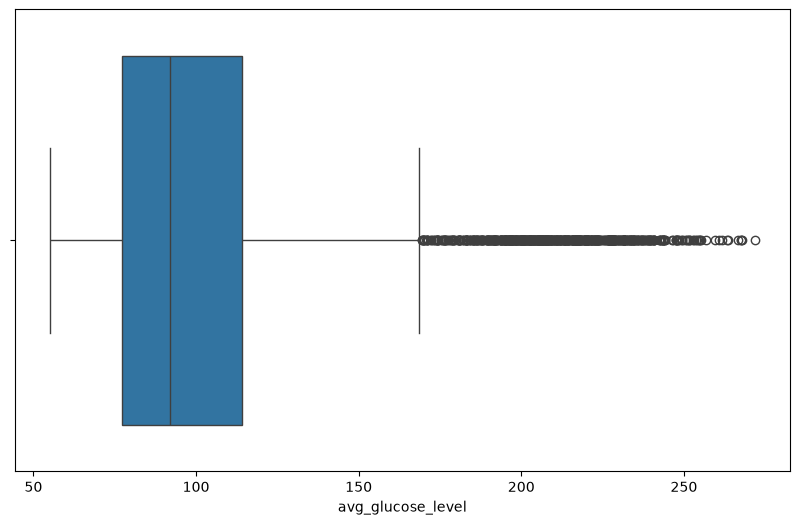

In [150]:
plt.figure(figsize=(10,6))

sns.boxplot(x=X_encoded['avg_glucose_level'])
plt.show()

In [151]:
X_encoded['avg_glucose_level'].describe()

count    5110.000000
mean      106.147677
std        45.283560
min        55.120000
25%        77.245000
50%        91.885000
75%       114.090000
max       271.740000
Name: avg_glucose_level, dtype: float64

In [152]:
X_encoded['avg_glucose_level']=pd.qcut(X_encoded['avg_glucose_level'],q=4,labels=['glucose_low', 'glucose_normal', 'glucose_prediabetes', 'glucose_high'])

In [153]:
X_encoded.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,9046,67.0,0,1,glucose_high,Obese,1,1,0,1,0,1,0,0,1,1,0,0
1,51676,61.0,0,0,glucose_high,Overweight,1,0,0,1,0,0,1,0,0,0,1,0
2,31112,80.0,0,1,glucose_prediabetes,Overweight,1,1,0,1,0,1,0,0,0,0,1,0
3,60182,49.0,0,0,glucose_high,Obese,1,0,0,1,0,1,0,0,1,0,0,1
4,1665,79.0,1,0,glucose_high,Normal,1,0,0,1,0,0,1,0,0,0,1,0


In [154]:
X_final = pd.get_dummies(X_encoded,columns=['bmi','avg_glucose_level'],drop_first=True)

In [155]:
X_final.head()

,id,age,hypertension,heart_disease,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,bmi_Normal,bmi_Overweight,bmi_Obese,avg_glucose_level_glucose_normal,avg_glucose_level_glucose_prediabetes,avg_glucose_level_glucose_high
0,9046,67.0,0,1,1,1,0,1,0,1,0,0,1,1,0,0,False,False,True,False,False,True
1,51676,61.0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,False,True,False,False,False,True
2,31112,80.0,0,1,1,1,0,1,0,1,0,0,0,0,1,0,False,True,False,False,True,False
3,60182,49.0,0,0,1,0,0,1,0,1,0,0,1,0,0,1,False,False,True,False,False,True
4,1665,79.0,1,0,1,0,0,1,0,0,1,0,0,0,1,0,True,False,False,False,False,True


In [156]:
X_final= X_final.astype(int)

In [157]:
X_final.head()

,id,age,hypertension,heart_disease,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,bmi_Normal,bmi_Overweight,bmi_Obese,avg_glucose_level_glucose_normal,avg_glucose_level_glucose_prediabetes,avg_glucose_level_glucose_high
0,9046,67,0,1,1,1,0,1,0,1,0,0,1,1,0,0,0,0,1,0,0,1
1,51676,61,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1
2,31112,80,0,1,1,1,0,1,0,1,0,0,0,0,1,0,0,1,0,0,1,0
3,60182,49,0,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,1
4,1665,79,1,0,1,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,0,1


In [165]:
col = ['age','id']

X_final[col]= scaler.fit_transform(X_final[col])

In [166]:
X_final.head()

,id,age,hypertension,heart_disease,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,bmi_Normal,bmi_Overweight,bmi_Obese,avg_glucose_level_glucose_normal,avg_glucose_level_glucose_prediabetes,avg_glucose_level_glucose_high
0,-1.298312,1.050950,0,1,1,1,0,1,0,1,0,0,1,1,0,0,0,0,1,0,0,1
1,0.716371,0.785835,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1
2,-0.255478,1.625367,0,1,1,1,0,1,0,1,0,0,0,0,1,0,0,1,0,0,1,0
3,1.118363,0.255604,0,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,1
4,-1.647136,1.581181,1,0,1,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,0,1


In [167]:
from scipy.stats import pearsonr

selected_features = X_final.drop(X_final['stroke'])

In [168]:
selected_features

,id,age,hypertension,heart_disease,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,bmi_Normal,bmi_Overweight,bmi_Obese,avg_glucose_level_glucose_normal,avg_glucose_level_glucose_prediabetes,avg_glucose_level_glucose_high
2,-0.255478,1.625367,0,1,1,1,0,1,0,1,0,0,0,0,1,0,0,1,0,0,1,0
3,1.118363,0.255604,0,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,1
4,-1.647136,1.581181,1,0,1,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,0,1
5,0.952339,1.669553,0,0,1,1,0,1,0,1,0,0,1,1,0,0,0,1,0,0,0,1
6,0.820627,1.360251,1,1,1,1,0,1,0,1,0,0,0,0,1,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5105,-0.864089,1.625367,1,0,0,0,0,1,0,1,0,0,1,0,1,0,0,1,0,1,0,0
5106,0.394863,1.669553,0,0,0,0,0,1,0,0,1,0,1,0,1,0,0,0,1,0,0,1
5107,-0.793720,-0.362999,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,1,0,1,0,0
5108,0.048497,0.343976,0,0,0,1,0,1,0,1,0,0,0,1,0,0,1,0,0,0,0,1


In [169]:
correlations = {
    feature : pearsonr(X_final[feature], X_final['stroke'])[0]
    for feature in selected_features
}

In [170]:
correlations

{'id': np.float64(0.006388170005145293),
 'age': np.float64(0.24512807609653586),
 'hypertension': np.float64(0.1279038234664799),
 'heart_disease': np.float64(0.13491399696869266),
 'stroke': np.float64(1.0),
 'gender_Male': np.float64(0.009117154023008615),
 'gender_Other': np.float64(-0.003166422855664945),
 'ever_married_Yes': np.float64(0.10833974165701035),
 'work_type_Never_worked': np.float64(-0.014882457537542762),
 'work_type_Private': np.float64(0.011888235156031466),
 'work_type_Self-employed': np.float64(0.062168257271196625),
 'work_type_children': np.float64(-0.08386926606516604),
 'Residence_type_Urban': np.float64(0.015457965477256827),
 'smoking_status_formerly smoked': np.float64(0.06455557529819721),
 'smoking_status_never smoked': np.float64(-0.004128687879042905),
 'smoking_status_smokes': np.float64(0.008939203206270004),
 'bmi_Normal': np.float64(0.009499397315036616),
 'bmi_Overweight': np.float64(0.0779400861557428),
 'bmi_Obese': np.float64(-0.005359420911019

In [171]:
correlations_df = pd.DataFrame(list(correlations.items()),columns=['Feature','Pearson Correlation'])

In [172]:
correlations_df.sort_values(by='Pearson Correlation', ascending=False)

,Feature,Pearson Correlation
4,stroke,1.000000
1,age,0.245128
3,heart_disease,0.134914
2,hypertension,0.127904
7,ever_married_Yes,0.108340
21,avg_glucose_level_glucose_high,0.096098
17,bmi_Overweight,0.077940
13,smoking_status_formerly smoked,0.064556
10,work_type_Self-employed,0.062168
12,Residence_type_Urban,0.015458


In [176]:
X_final.head()

cols = X_final.drop(X_final['stroke']).columns

In [177]:
cols

Index(['id', 'age', 'hypertension', 'heart_disease', 'stroke', 'gender_Male',
       'gender_Other', 'ever_married_Yes', 'work_type_Never_worked',
       'work_type_Private', 'work_type_Self-employed', 'work_type_children',
       'Residence_type_Urban', 'smoking_status_formerly smoked',
       'smoking_status_never smoked', 'smoking_status_smokes', 'bmi_Normal',
       'bmi_Overweight', 'bmi_Obese', 'avg_glucose_level_glucose_normal',
       'avg_glucose_level_glucose_prediabetes',
       'avg_glucose_level_glucose_high'],
      dtype='str')

In [178]:
from scipy.stats import chi2_contingency

In [191]:
from scipy.stats import chi2_contingency

alpha = 0.05

chi2_results = {}

for col in cols:
    contingency = pd.crosstab(X_final[col], X_final['stroke'])

    chi2_stat, p_val, _, _ = chi2_contingency(contingency)

    decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Fail to Reject Null (Drop)'

    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }

In [192]:
chi2_df = pd.DataFrame.from_dict(
    chi2_results,
    orient='index'
)

chi2_df.index.name = 'Feature'

chi2_df = chi2_df.sort_values(by='p_value')

print(chi2_df)

                                       chi2_statistic  ...                    Decision
Feature                                                ...                            
stroke                                    5088.449457  ...  Reject Null (Keep Feature)
age                                        489.331231  ...  Reject Null (Keep Feature)
heart_disease                               90.259561  ...  Reject Null (Keep Feature)
hypertension                                81.605368  ...  Reject Null (Keep Feature)
ever_married_Yes                            58.923890  ...  Reject Null (Keep Feature)
avg_glucose_level_glucose_high              46.164989  ...  Reject Null (Keep Feature)
work_type_children                          34.811139  ...  Reject Null (Keep Feature)
bmi_Overweight                              30.209697  ...  Reject Null (Keep Feature)
smoking_status_formerly smoked              20.510529  ...  Reject Null (Keep Feature)
work_type_Self-employed                    

In [195]:
X = X_final.drop(columns=['Residence_type_Urban','work_type_Private','id','bmi_Normal', 'gender_Male','work_type_Never_worked','smoking_status_smokes','bmi_Obese','smoking_status_never smoked','gender_Other'])

In [196]:
X.head()

,age,hypertension,heart_disease,stroke,ever_married_Yes,work_type_Self-employed,work_type_children,smoking_status_formerly smoked,bmi_Overweight,avg_glucose_level_glucose_normal,avg_glucose_level_glucose_prediabetes,avg_glucose_level_glucose_high
0,1.050950,0,1,1,1,0,0,1,0,0,0,1
1,0.785835,0,0,1,1,1,0,0,1,0,0,1
2,1.625367,0,1,1,1,0,0,0,1,0,1,0
3,0.255604,0,0,1,1,0,0,0,0,0,0,1
4,1.581181,1,0,1,1,1,0,0,0,0,0,1


In [202]:
X_use = X.drop(columns=['stroke'])

In [203]:
X_use

,age,hypertension,heart_disease,ever_married_Yes,work_type_Self-employed,work_type_children,smoking_status_formerly smoked,bmi_Overweight,avg_glucose_level_glucose_normal,avg_glucose_level_glucose_prediabetes,avg_glucose_level_glucose_high
2,1.625367,0,1,1,0,0,0,1,0,1,0
3,0.255604,0,0,1,0,0,0,0,0,0,1
4,1.581181,1,0,1,1,0,0,0,0,0,1
5,1.669553,0,0,1,0,0,1,1,0,0,1
6,1.360251,1,1,1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
5105,1.625367,1,0,1,0,0,0,1,1,0,0
5106,1.669553,0,0,1,1,0,0,0,0,0,1
5107,-0.362999,0,0,1,1,0,0,1,1,0,0
5108,0.343976,0,0,1,0,0,1,0,0,0,1


In [209]:
X_use.shape

(5108, 11)

In [210]:
y_use = X['stroke']

In [211]:
y_use.shape

(5108,)

In [207]:
from sklearn.model_selection import train_test_split

In [212]:
X_train, X_test, y_train, y_test = train_test_split(X_use, y_use, test_size=0.20, random_state=42)  

In [213]:
from sklearn.linear_model import LogisticRegression

In [214]:
model = LogisticRegression()

In [215]:
model.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [217]:
y_pred = model.predict(X_test)

In [218]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(1022,))

In [219]:
y_test

3562    0
1422    0
1407    0
4355    0
748     0
       ..
4754    0
4105    0
3527    0
804     0
4952    0
Name: stroke, Length: 1022, dtype: int64

In [220]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [222]:
accuracy_score(y_test,y_pred)
confusion_matrix(y_test,y_pred)
classification_report(y_test,y_pred)

print(classification_report)

<function classification_report at 0x115d8e140>


/Users/tusharrr/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/tusharrr/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/tusharrr/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

In [223]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.94      1.00      0.97       961
           1       0.00      0.00      0.00        61

    accuracy                           0.94      1022
   macro avg       0.47      0.50      0.48      1022
weighted avg       0.88      0.94      0.91      1022



/Users/tusharrr/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/tusharrr/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/tusharrr/Library/Python/3.14/lib/python/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

In [224]:
accuracy_score(y_test,y_pred)
confusion_matrix(y_test,y_pred)

array([[961,   0],
       [ 61,   0]])

In [225]:
accuracy_score(y_test,y_pred)

0.9403131115459883

In [226]:
confusion_matrix(y_test,y_pred)

array([[961,   0],
       [ 61,   0]])

In [227]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [228]:
confusion_matrix(y_test,y_pred)

array([[693, 268],
       [  7,  54]])

In [229]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.99      0.72      0.83       961
           1       0.17      0.89      0.28        61

    accuracy                           0.73      1022
   macro avg       0.58      0.80      0.56      1022
weighted avg       0.94      0.73      0.80      1022

